# Ji et al. 2020 — Cutaneous SCC · 02 Manifold

scFates principal-tree (PPT) fit to the cell-state manifold, biologically-motivated rooting, and pseudotime. **Topology decision:** the embryonic modules resolve onto a **branching** hub-and-spoke (Gate 2 reasoning in 03) — a scFates **tree** is used, not a curve.

A large cycling compartment (~35% of cells; MKI67/TOP2A) dominates the whole-manifold PPT and forces an unstable fit. Following the reference branching protocol (Filbin 2018), the trajectory is scoped to the **developmental (non-cycling) compartment**; the cycling cells are a proliferation confound orthogonal to the embryonic modules, not developmental signal.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)

### Load processed data

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

AnnData object with n_obs × n_vars = 10531 × 1443
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Score embryonic modules (for rooting + smoothing)
Gast / pSom / Crest scored with the union control pool (`score_genes`), on the full malignant set; graph-smoothed over the kNN graph before geography/rooting (Chen 2020 raw-score lesson).

In [4]:
import glob
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'].loc[feat_dict['union'].isin(adata.raw.var_names)]
adata_full = adata.raw.to_adata(); adata_full.obs = adata.obs
for src, df_src in feat_dict.items():
    if src == 'union': continue
    g = df_src.loc[df_src.isin(adata_full.var_names)]
    sc.tl.score_genes(adata_full, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    adata.obs[src] = adata_full.obs[src].values
    print(src, g.size, g_ref.size)

GSE162534 76 224
GSE229103 88 224
rRNAModifications 101 224


### Scope to the developmental compartment
Cycling cells (phase != 'Not cycling') are a proliferation confound: the cycling score is orthogonal to the embryonic modules, and the cycling bridge destabilises the whole-manifold PPT. The trajectory is fit on the non-cycling developmental compartment, re-embedded (PCA -> Harmony theta=5 -> UMAP), which is a single connected component and fold-free (node-centroid UMAP~PCA distance correlation 0.97).

In [5]:
dev = (adata.obs.cell_cycle_phase == 'Not cycling').values
print('developmental (non-cycling) cells:', int(dev.sum()), '/', adata.n_obs)
a = adata[dev].copy()
sc.pp.pca(a, n_comps = 50)
sce.pp.harmony_integrate(a, 'sample', theta = 5, max_iter_harmony = 20)
sc.pp.neighbors(a, n_pcs = 20, n_neighbors = 30, use_rep = 'X_pca_harmony')
sc.tl.umap(a, spread = 1.3)

developmental (non-cycling) cells: 6800 / 10531


In [6]:
# graph-smooth the module scores over the developmental kNN graph
A = a.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0] = 1
for src in ['GSE162534', 'GSE229103', 'rRNAModifications']:
    a.obs[src + '_sm'] = (A @ a.obs[src].values) / deg
import scipy.sparse as sp
ncomp, _ = sp.csgraph.connected_components(a.obsp['distances'], directed=False)
print('developmental kNN components:', ncomp)

developmental kNN components: 1


### Fit the principal tree (branching)
scFates PPT tree on the developmental UMAP. Nodes/lambda/sigma set to the reference scale (lambda=2000, sigma=0.5); Nodes=50 gives a stable hub-and-spoke (3 forks, 5 tips).

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:   2%|2         | 1/50 [00:00<00:37,  1.32it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.


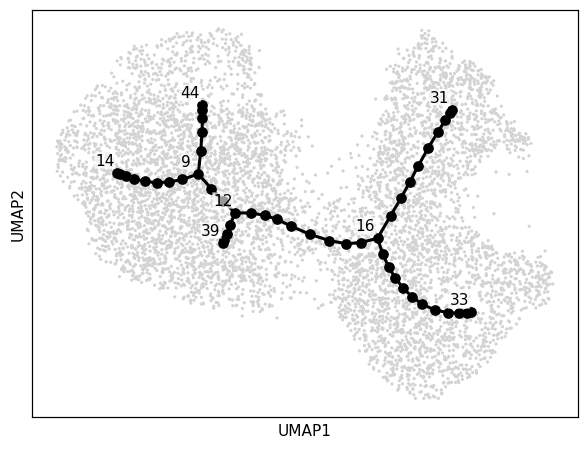

In [7]:
scf.tl.tree(a, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=0.5,
            use_rep='X_umap', seed=1, plot=True, basis='umap')

### Root at the Gast/pSom-high hub
The root is the topological convergence node with maximal joint (Gast+pSom) smoothed score and low Crest — the Gast/pSom-high, Crest-low developmental origin (Crest is developmentally *late*, a terminal readout, so it does **not** root the tree; Kürten rooting lesson).

In [8]:
node = np.asarray(a.obsm['X_R'].argmax(1)).ravel()
gm = pd.DataFrame({'node': node,
                   'G': a.obs['GSE162534_sm'].values,
                   'P': a.obs['GSE229103_sm'].values,
                   'C': a.obs['rRNAModifications_sm'].values}).groupby('node').mean()
gz = (gm - gm.mean()) / gm.std()
root = int((gz.G + gz.P).idxmax())
print('root (hub) node:', root, '| z(Gast,pSom,Crest) =', gz.loc[root].round(2).to_dict())
scf.tl.root(a, root)
scf.tl.pseudotime(a, seed = 1)

root (hub) node: 14 | z(Gast,pSom,Crest) = {'G': 1.82, 'P': 1.8, 'C': -2.24}
node 14 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:04) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


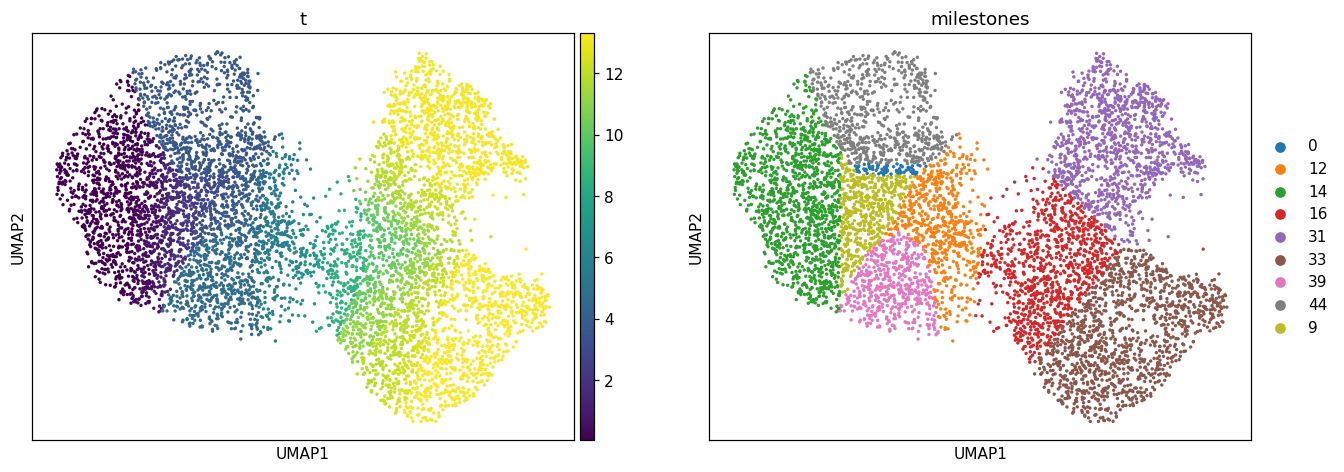

In [9]:
sc.pl.umap(a, color = ['t', 'milestones'], size = 20)

### Rename milestones
Milestones renamed by role: the Gast/pSom-high **Hub** (root), the **Gast-arm** and **pSom-arm** terminals, read off the smoothed module scores (data-driven, not subtype names).

In [10]:
# per-milestone module identity
ms = a.obs.groupby('milestones', observed=True).agg(
        t=('t','mean'), G=('GSE162534_sm','mean'), P=('GSE229103_sm','mean'), C=('rRNAModifications_sm','mean'))
ms['GmP'] = ms.G - ms.P
print(ms.round(3).sort_values('t').to_string())

                 t      G      P      C    GmP
milestones                                    
14           0.204  0.005  0.060 -0.001 -0.054
9            2.286 -0.006  0.038  0.025 -0.044
0            3.520 -0.018  0.044  0.031 -0.062
44           3.666 -0.019  0.060  0.017 -0.079
39           4.681  0.007  0.031  0.013 -0.024
12           5.115 -0.023  0.027  0.044 -0.050
16           9.981 -0.022  0.025  0.029 -0.047
31          12.839 -0.047  0.072  0.013 -0.119
33          12.852 -0.029  0.025  0.028 -0.054


milestone map: {'14': 'Hub', '39': 'Gast_arm', '31': 'pSom_arm'}


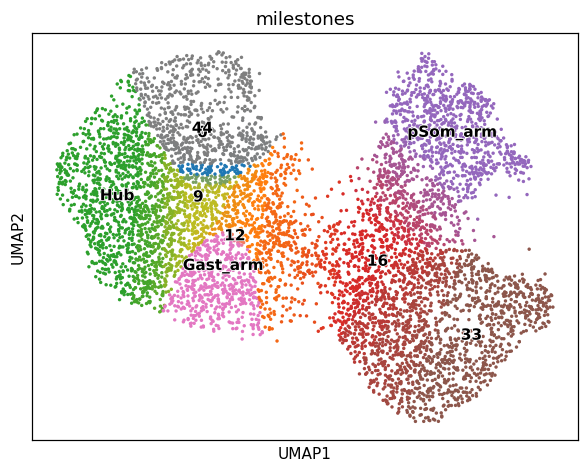

In [11]:
# name root as Hub; the most Gast-leaning terminal as Gast_arm; most pSom-leaning as pSom_arm
B = a.uns['graph']['B']; degn = (B>0).sum(1)
tips = [int(t) for t in np.where(degn==1)[0]]
tip_gmp = {str(t): (gz.G[t]-gz.P[t]) for t in tips if t in gz.index}
gast_tip = max(tip_gmp, key=tip_gmp.get)
psom_tip = min(tip_gmp, key=tip_gmp.get)
new = {str(root): 'Hub'}
new[gast_tip] = 'Gast_arm'
new[psom_tip] = 'pSom_arm'
scf.tl.rename_milestones(a, new = new)
print('milestone map:', new)
scf.pl.milestones(a, basis='umap', annotate=True, s=20)

### Save manifold + figure

In [12]:
a.write(os.path.join(pth_in, 'manifold.h5ad'))

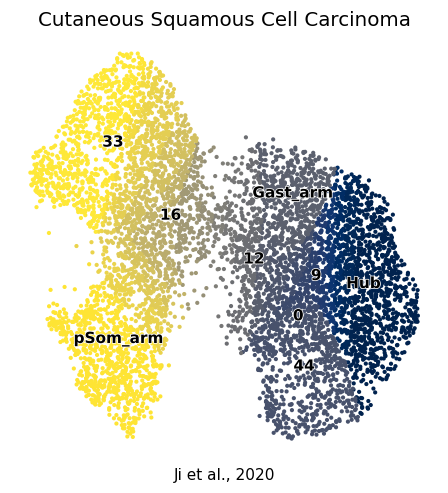

In [13]:
# manifold embedding figure (reference style: pseudotime + milestone labels)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(a, color = 't', cmap = 'cividis', size = 30, colorbar_loc = None,
           frameon = False, show = False, ax = ax)
sc.pl.umap(a, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Cutaneous Squamous Cell Carcinoma', size = 13)
ax.text(.5, -.05, 'Ji et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_out, 'manifold.pdf'), bbox_inches = 'tight')